# 01 - Exploratory analysis

Descriptive and diagnostic analytics for the study districts. All numbers are produced by `make analytics-eda` from the PostgreSQL warehouse; this notebook only displays them. Check the data-status banner first.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 200)
ROOT = Path.cwd()
findings = (ROOT / 'docs' / 'FINDINGS.md').read_text(encoding='utf-8')
display(Markdown(findings))

# Findings: climate, weather and crop yield in the study districts

> **SYNTHETIC DATA IN USE: `satellite_16d` (100% synthetic).** Findings that depend on these tables are flagged below.
> Weather sources (share of district-days for rain): IMD grid 0%, NASA POWER 100%, synthetic 0%.

Generated by `python -m analytics.make_findings` from `reports/analytics/*.json`; every number comes from the PostgreSQL warehouse. Unit of analysis: yield-reporting district units (see `docs/DECISIONS.md` D-006).

## Five most important findings

1. **Monsoon-season rainfall is highly variable and most variable in the dry south.** The coefficient of variation of kharif rainfall averages 0.26 across 51 districts (1991-2024), against 0.64 for rabi. The most variable district is Kanyakumari (CV 0.44, mean 804 mm); the most stable is Dakshina Kannada (CV 0.17). Across districts, mean rainfall and CV have Spearman rho = -0.23 (p = 0.098). The driest regional years were 2018 (94% of districts below normal), 2015 (94% of districts below normal), 2016 (76% of districts below normal).
2. **Yields are trending up for most crops, but not everywhere.** Of 13 state-crop series (1991-2017, balanced district panels), 8 show a significant increase and 1 a significant decrease (Mann-Kendall, p < 0.05). Rice rises significantly in 3 of 4 states (Andhra Pradesh +0.045 t/ha/yr, +1.5%/yr, Karnataka +0.023 t/ha/yr, +0.9%/yr, Telangana +0.045 t/ha/yr, +1.6%/yr); the steepest relative gain is cotton in Telangana (+3.2% of mean per year).
3. **Kharif droughts (season rain < 75% of the district mean) hit about one season in 6.** Mean frequency is 17.3% of 34 seasons; Kanyakumari is most exposed (14 events, 41%). The worst regional years were 2015 (57% of districts), 2018 (57% of districts), 2016 (51% of districts). Under the strict flood-risk definition (> 125% of mean and >= 3 days > 100 mm of district-mean rain) there were only 9 events in 7 districts, because district-area-mean rainfall rarely exceeds 100 mm/day.
4. **What weather explains about yield depends on how you look, and it is not much.** Pooled across districts, rice yield and kharif rainfall have Pearson r = -0.19 (95% cluster-bootstrap CI -0.32 to -0.06); within districts, after removing each district's level and trend, r = 0.15 (0.08 to 0.23). The sign flips: wetter districts yield less rice, but a wetter year helps a given district (spatial confounding, so pooled correlations are misleading). In the two-way fixed-effects regression (district and year effects, district-clustered SEs, n = 918), +100 mm of rainfall has no statistically detectable association with yield (+0.006 t/ha, p = 0.335) and +1 C of mean Tmax is associated with lower yield (-0.087 t/ha, p = 0.006); in the district-FE-plus-trend model Tmax is -0.116 t/ha (p < 0.001) and rain -0.001 t/ha (p = 0.878). Weather terms add only 0.4% of R-squared beyond district and year effects, which sets a low ceiling for any weather-based yield forecast.
5. **Districts fall into 6 climate groups** (KMeans, silhouette 0.33, features from years <= 2011 only): dry-hot (3 districts, mean kharif rain 433 mm, e.g. Coimbatore, Thanjavur); moderate-warm-variable-rain-volatile-yield (5 districts, mean kharif rain 653 mm, e.g. Belgaum, Bidar); moderate-warm-variable-rain (27 districts, mean kharif rain 674 mm, e.g. Ananthapur, Bangalore); moderate-warm-stable-rain (6 districts, mean kharif rain 810 mm, e.g. Adilabad, Karimnagar); moderate-cool (6 districts, mean kharif rain 1038 mm, e.g. Hassan, Mandya); wet-cool (4 districts, mean kharif rain 2746 mm, e.g. Chickmagalur, Coorg).

## Rice: fixed-effects regression

| model | term | coef | SE (cluster) | p | % of mean yield per 1 SD | VIF (within) |
| --- | --- | --- | --- | --- | --- | --- |
| M1_twoway_FE_weather | rain_100mm | 0.0056 | 0.0058 | 0.3354 | 0.4654 | 1.3034 |
| M1_twoway_FE_weather | tmax_c | -0.0874 | 0.0317 | 0.0058 | -2.4519 | 1.3034 |
| M2_twoway_FE_weather_satellite | rain_100mm | 0.0083 | 0.0060 | 0.1616 | 0.6933 | 1.3329 |
| M2_twoway_FE_weather_satellite | tmax_c | -0.1116 | 0.0513 | 0.0294 | -3.1312 | 4.0826 |
| M2_twoway_FE_weather_satellite | ndvi_01 | -0.1005 | 0.0312 | 0.0013 | -1.6822 | 1.6262 |
| M2_twoway_FE_weather_satellite | soilm_01 | 0.0342 | 0.0840 | 0.6834 | 0.4714 | 3.7845 |
| M3_district_FE_trend_weather | rain_100mm | -0.0009 | 0.0061 | 0.8783 | -0.0773 | 1.5252 |
| M3_district_FE_trend_weather | tmax_c | -0.1161 | 0.0219 | 0.0000 | -3.2573 | 1.5252 |

Max within-FE VIF per model: M1_twoway_FE_weather 1.5, M2_twoway_FE_weather_satellite 4.2, M3_district_FE_trend_weather 1.7. Full tables: `reports/analytics/regression_coefficients.csv`, `correlations.csv`, `yield_trends_table.csv`.

## Figures

- `reports/figures/rainfall_anomaly_heatmap.png` (and `.html` where interactive): kharif rainfall anomaly, districts x years
- `reports/figures/rainfall_cv_kharif.png` (and `.html` where interactive): kharif rainfall variability map
- `reports/figures/yield_trends.png` (and `.html` where interactive): state yield trends with Theil-Sen fits
- `reports/figures/drought_flood_frequency.png` (and `.html` where interactive): drought and flood-risk frequency maps
- `reports/figures/correlations_within.png` (and `.html` where interactive): within-district weather-yield correlations
- `reports/figures/regression_residuals.png` (and `.html` where interactive): regression residuals
- `reports/figures/clusters_map.png` (and `.html` where interactive): climate-vulnerability clusters

## Limitations

- **Ecological fallacy and aggregation.** All relationships are between district-level averages. They describe districts, not farms or villages, and say nothing certain about individual farmers.
- **District units are approximate.** Yields refer to ICRISAT's 1966 parent districts; our polygons are reconstructed from 2021 boundaries (D-006). Weather is averaged over those polygons.
- **Spatial dependence.** District mean yields are spatially autocorrelated (Moran's I, k = 5 neighbours: rice 0.18 (p = 0.018), wheat 0.25 (p = 0.008), cotton 0.10 (p = 0.083), sugarcane 0.67 (p = 0.001)), so the effective sample size is smaller than the number of districts and p-values are optimistic even with district-clustered errors.
- **Association, not causation.** Fixed effects remove district levels and common year shocks, but not time-varying confounders such as irrigation expansion, varieties or prices.
- **Year effects absorb regional weather.** Model M1 (year FE) identifies weather effects only from differences between districts within a year; M3 (district FE + trend) uses common year-to-year variation. Compare both.
- **Season attribution.** ICRISAT gives annual crop totals; each crop is assigned to one season (D-007). Rice also grows in rabi, so 'kharif rice' is an annual average. Sugarcane values look like jaggery equivalent (D-007).
- **Source data errors.** 4286 crop rows kept after dropping implausible ones (D-012; list in `docs/DATA_QUALITY.md`).
- **Weather product.** Tmax/Tmin from IMD are 1-degree grids; NASA POWER is a ~0.5-degree reanalysis product. See provenance in `docs/DATA_QUALITY.md`.
- **SYNTHETIC satellite features.** NDVI and soil moisture are currently generated from rainfall (Google Earth Engine is not authenticated), so any NDVI or soil-moisture result (correlations, M2 terms, the NDVI-yield query) is circular and must not be read as independent evidence.


## Kharif rainfall anomalies, districts x years

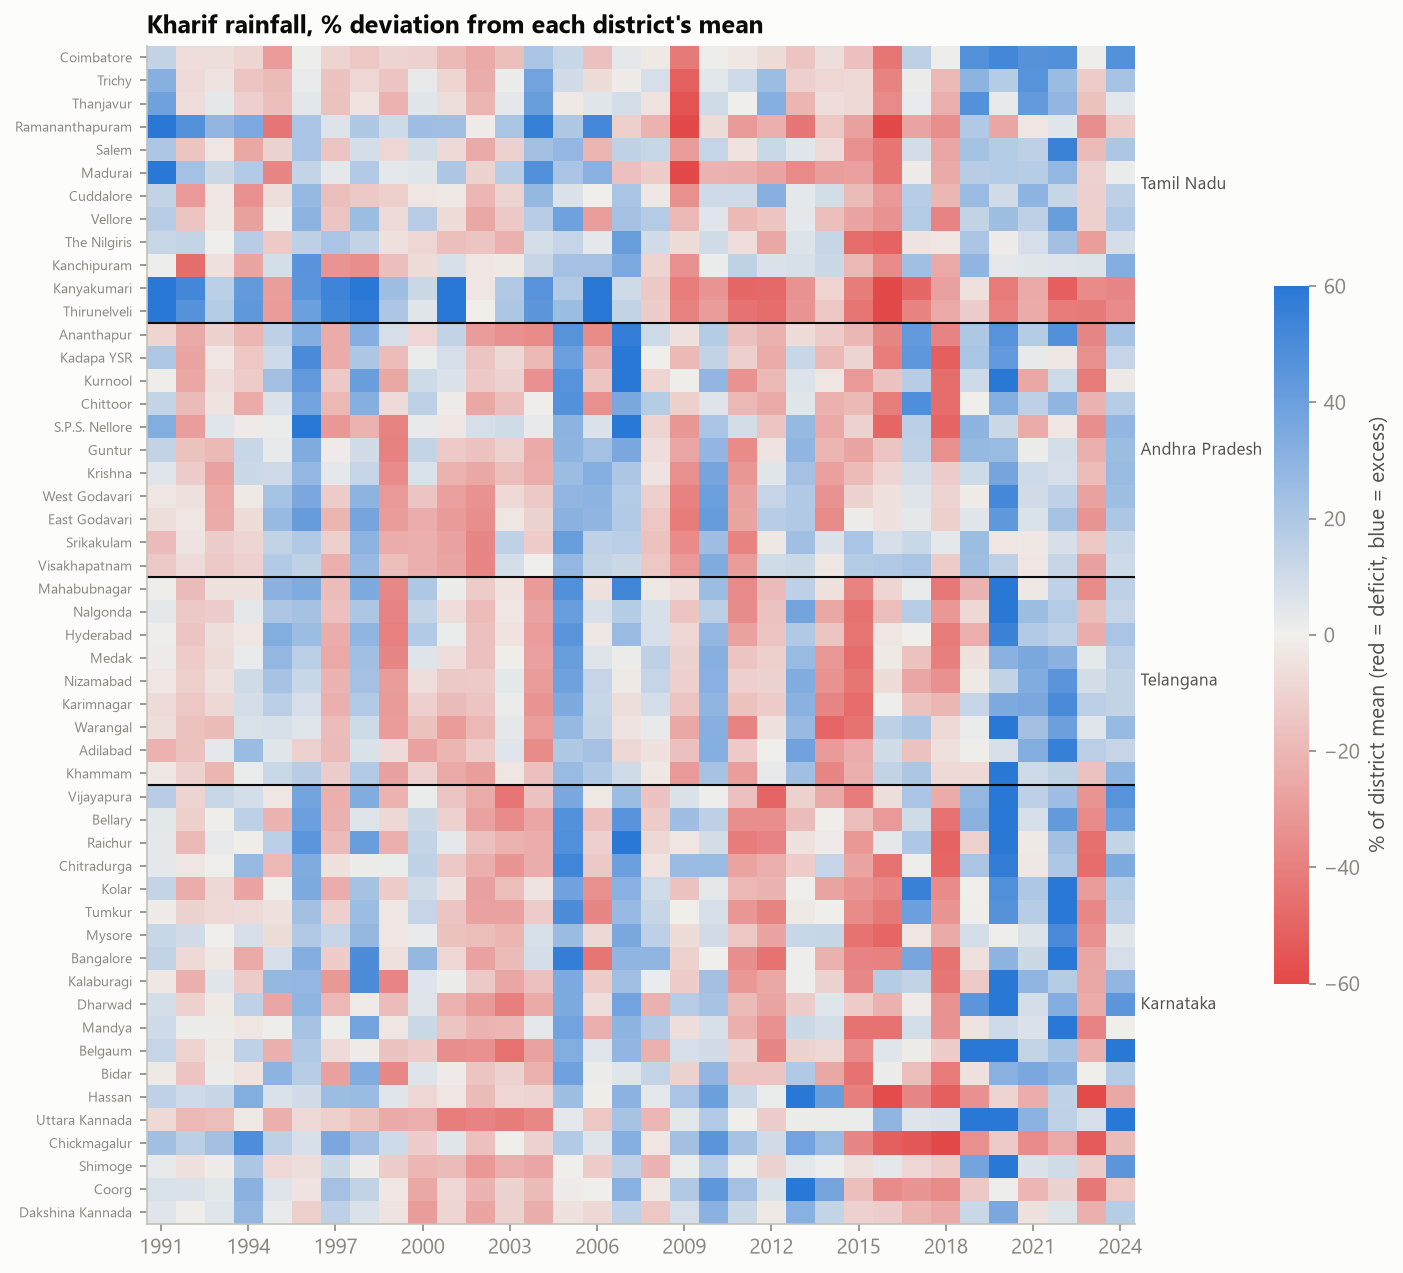

In [2]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'rainfall_anomaly_heatmap.png')))

## Kharif rainfall variability (CV)

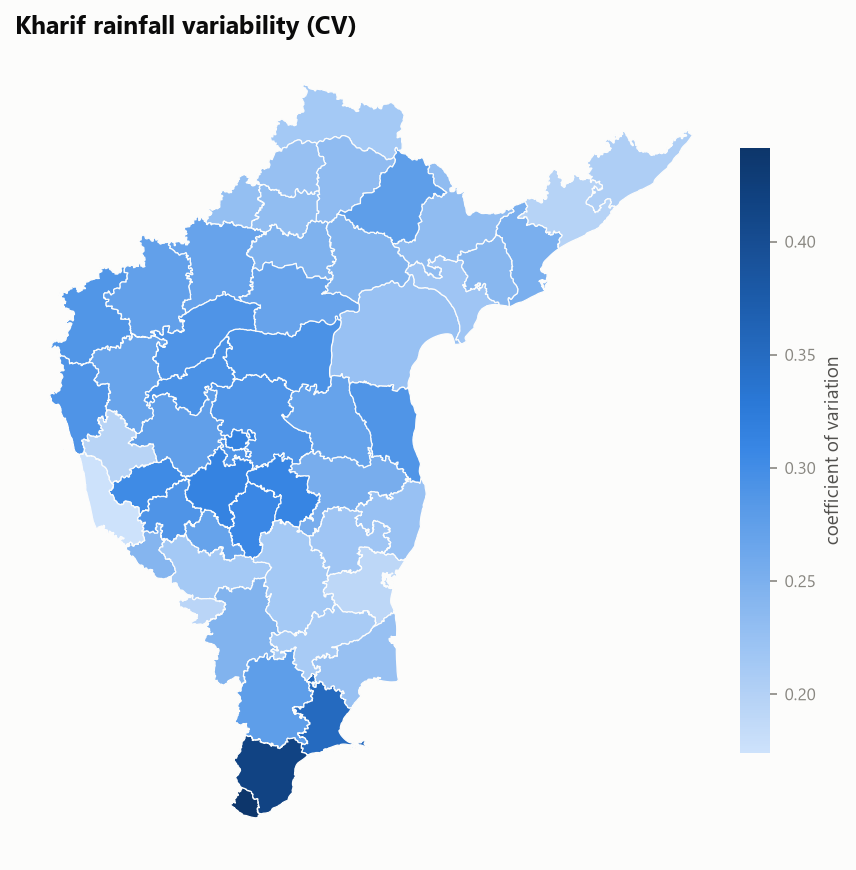

In [3]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'rainfall_cv_kharif.png')))

## State yield trends with Theil-Sen fits

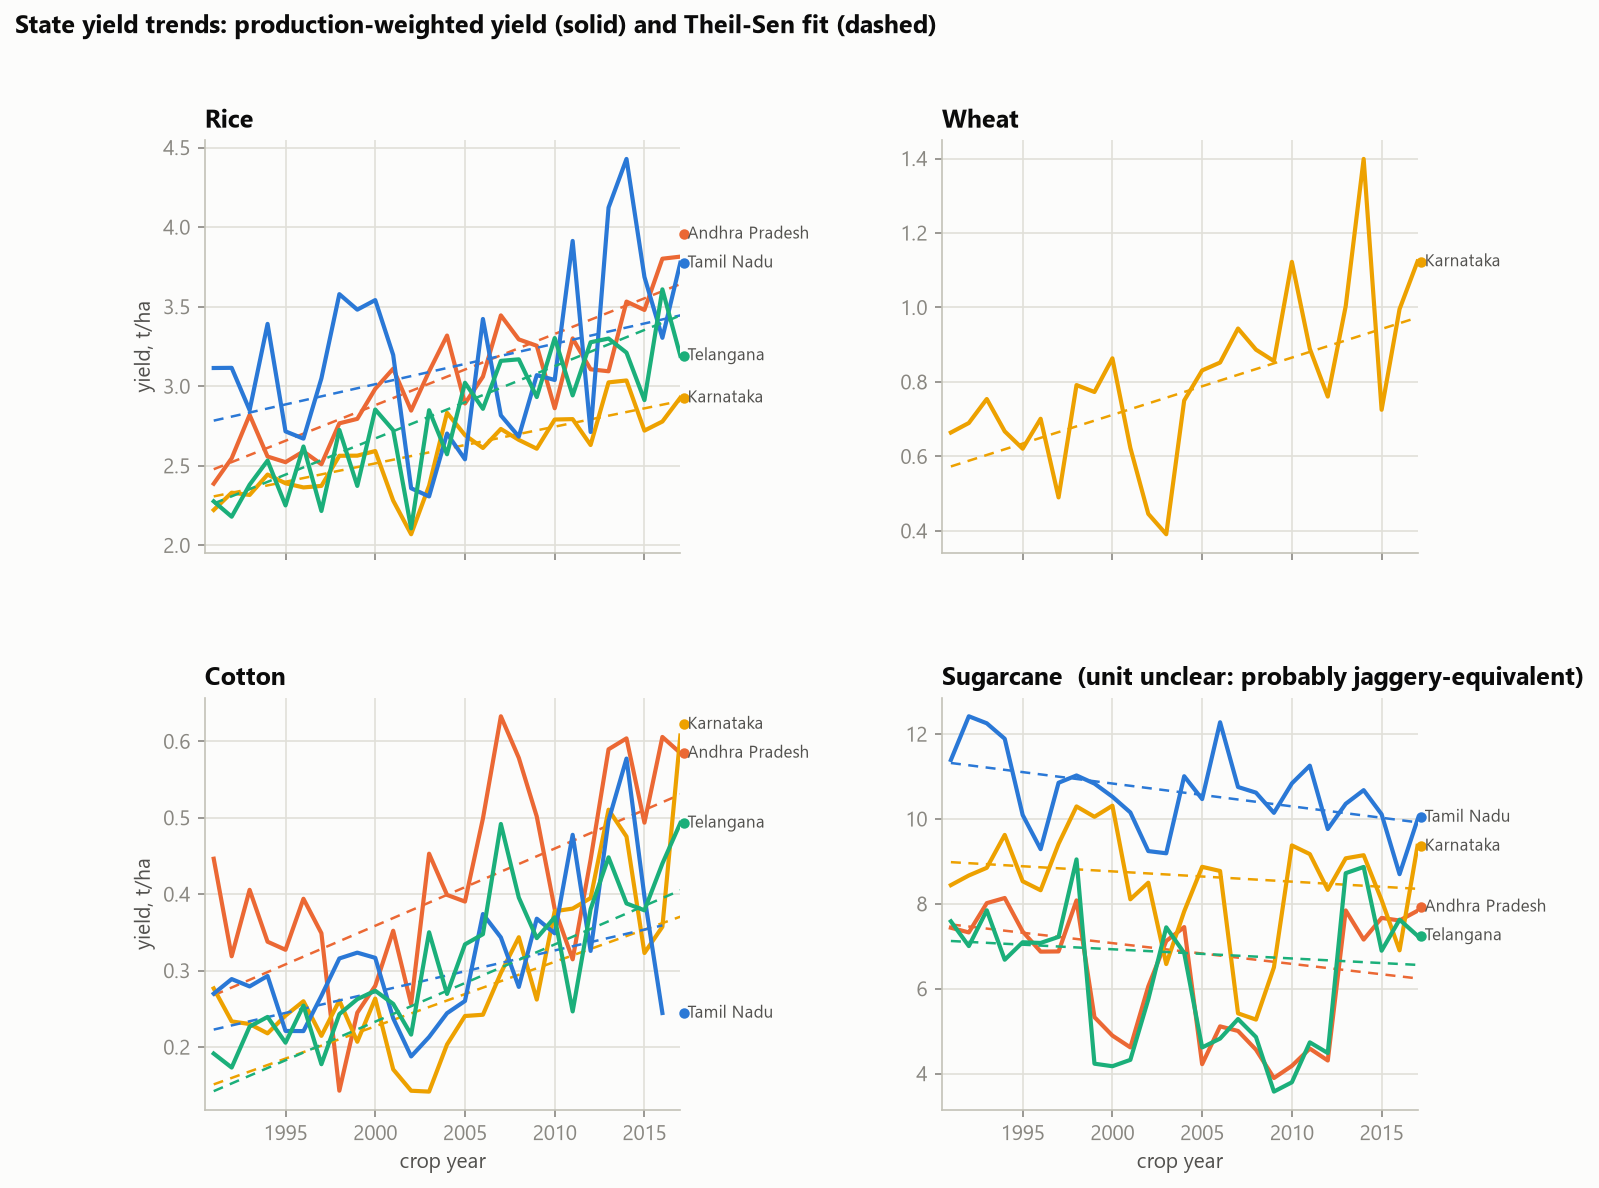

In [4]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'yield_trends.png')))

## Drought and flood-risk frequency

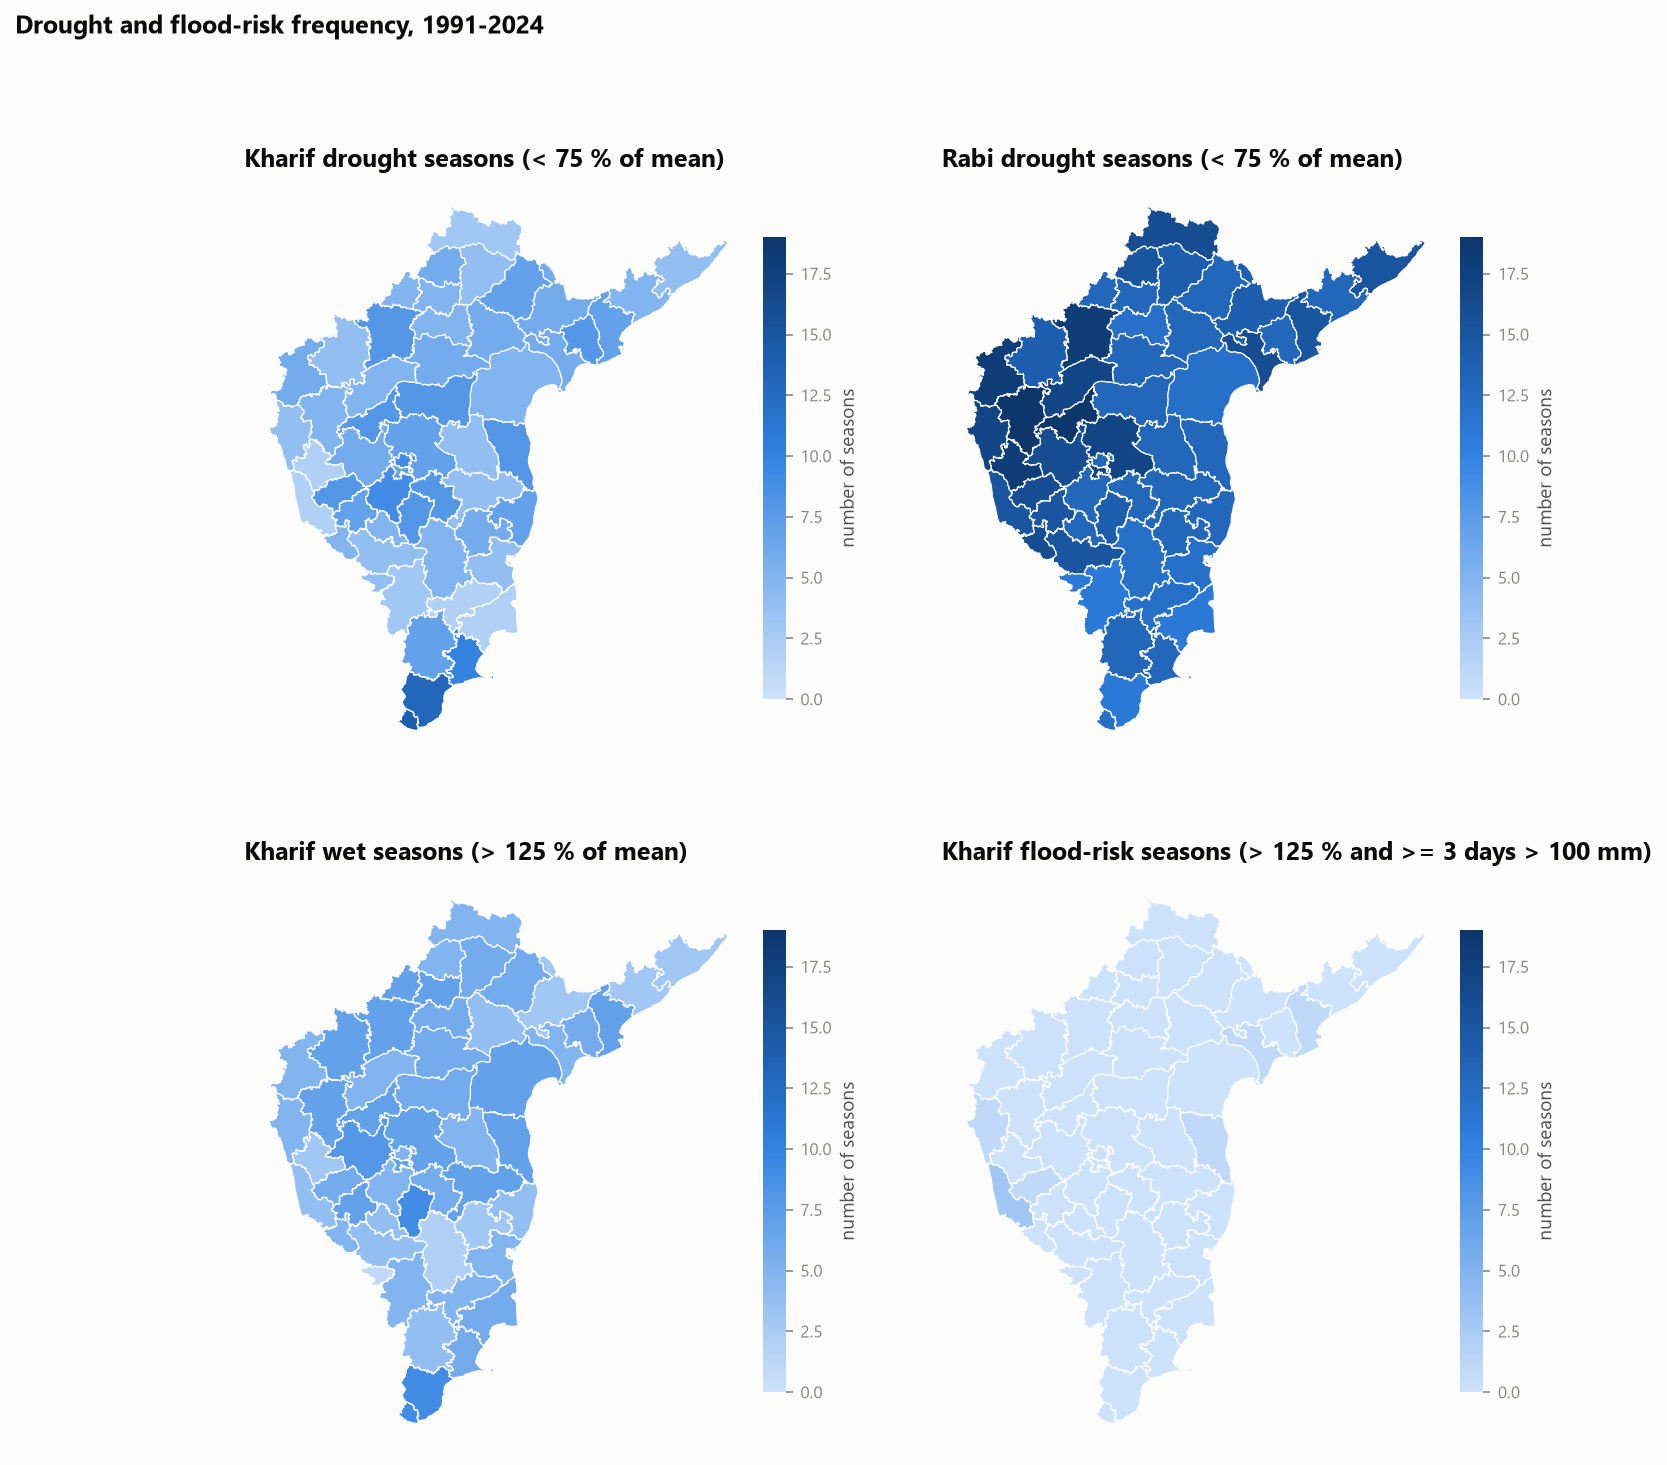

In [5]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'drought_flood_frequency.png')))

## Within-district weather-yield correlations

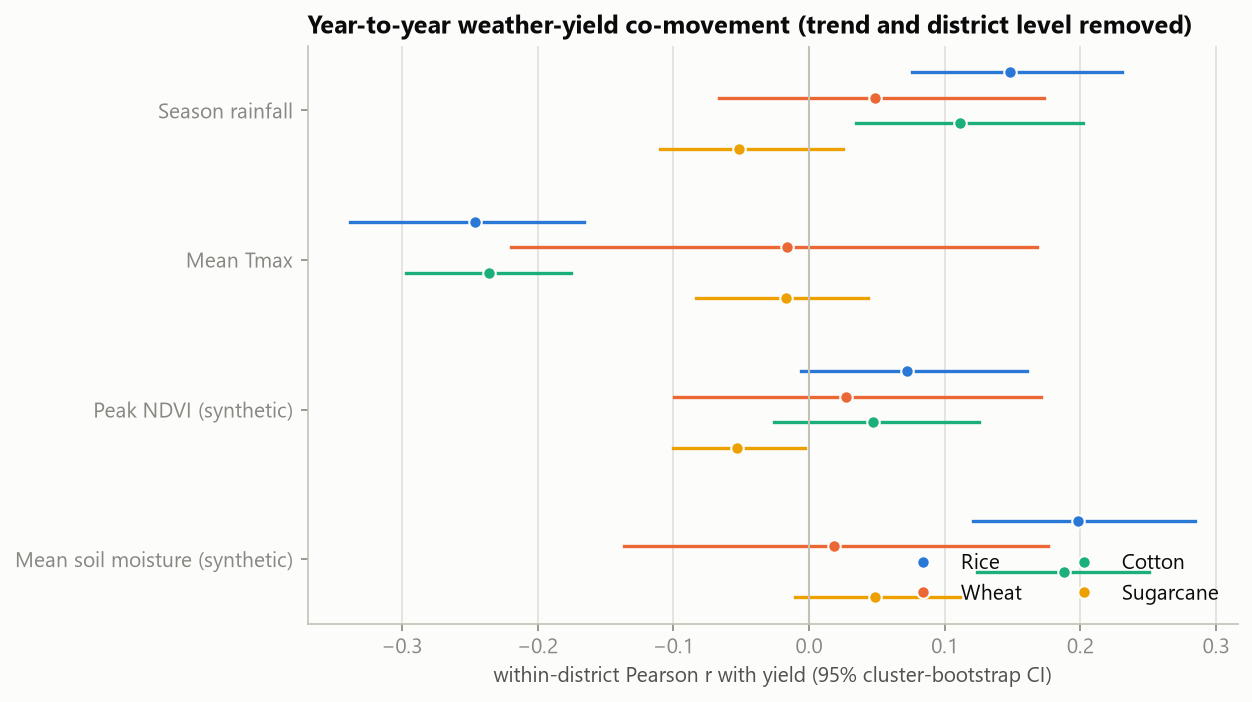

In [6]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'correlations_within.png')))

## Fixed-effects regression residuals

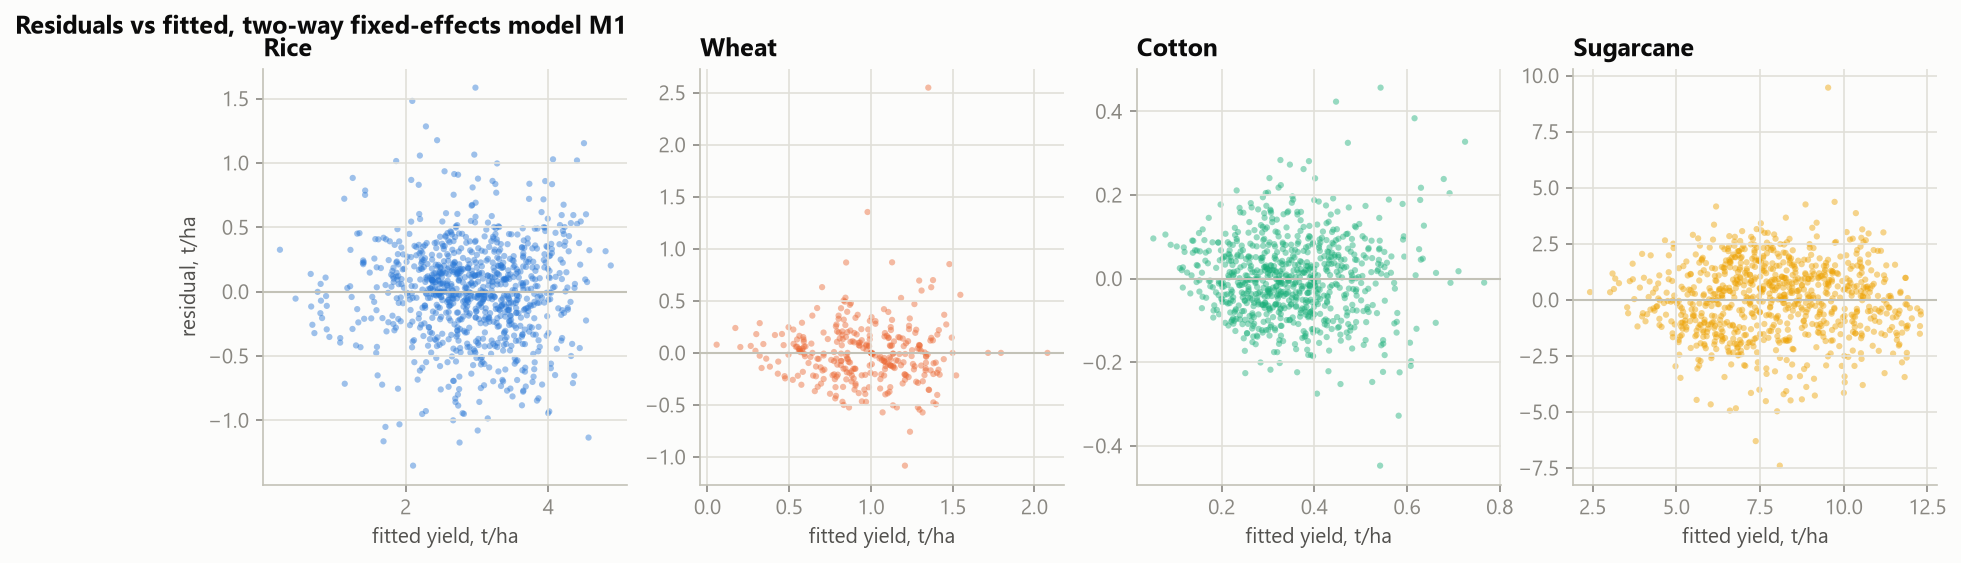

In [7]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'regression_residuals.png')))

## Climate-vulnerability clusters

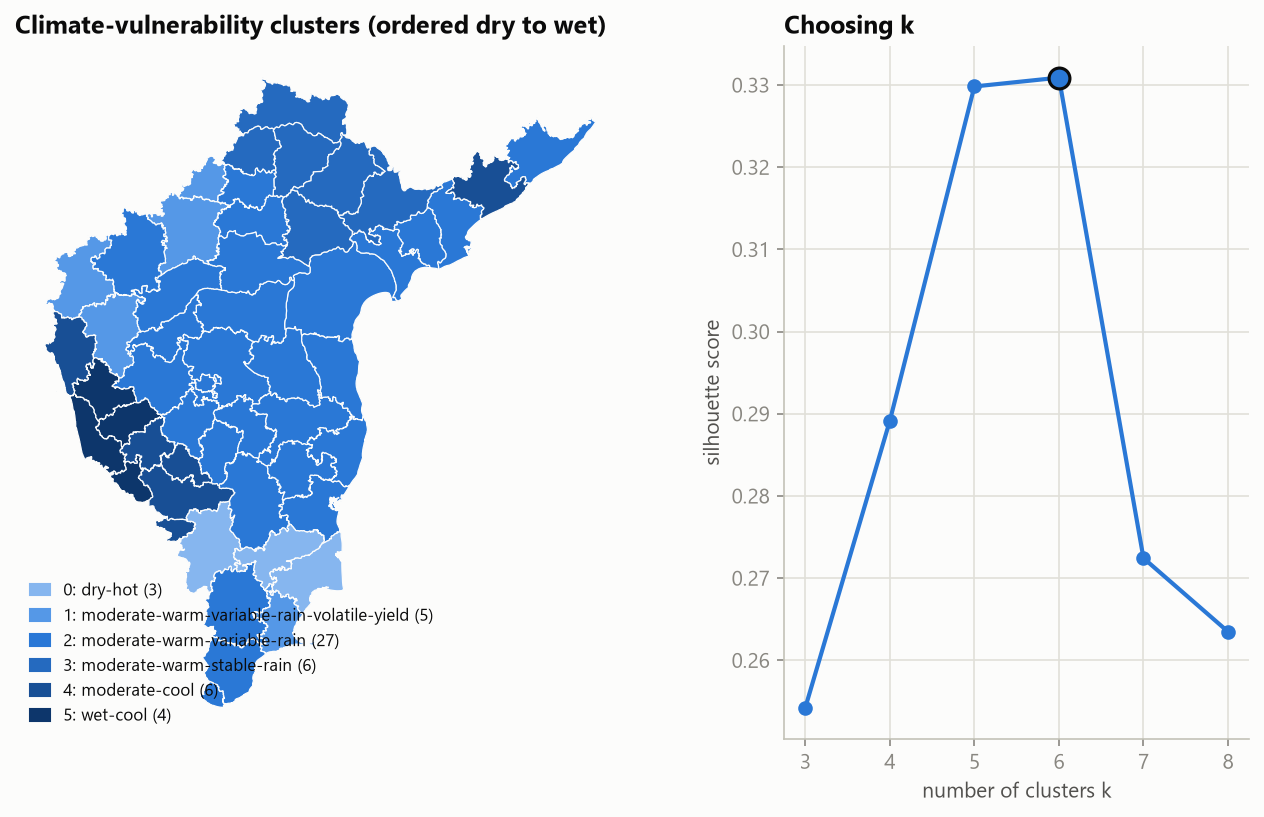

In [8]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'clusters_map.png')))

## Yield trends (Theil-Sen, Mann-Kendall)

In [9]:
pd.read_csv(ROOT / 'reports' / 'analytics' / 'yield_trends_table.csv').round(4)

,state,crop,n_years,n_districts,mean_yield_t_ha,slope_t_ha_per_year,slope_ci_lo,slope_ci_hi,slope_pct_of_mean_per_year,mk_tau,mk_p,mk_trend
0,Andhra Pradesh,rice,27,11,3.0291,0.0448,0.0330,0.0549,1.4776,0.7037,0.0000,increasing
1,Andhra Pradesh,cotton,27,8,0.4195,0.0101,0.0042,0.0153,2.4077,0.4245,0.0020,increasing
2,Andhra Pradesh,sugarcane,27,8,6.2808,-0.0489,-0.1647,0.0154,-0.7789,-0.1852,0.1821,no trend
3,Karnataka,rice,27,19,2.5826,0.0231,0.0184,0.0314,0.8931,0.6353,0.0000,increasing
4,Karnataka,wheat,27,7,0.8005,0.0154,0.0083,0.0221,1.9222,0.5043,0.0002,increasing
5,Karnataka,cotton,27,13,0.2918,0.0084,0.0041,0.0134,2.8918,0.4758,0.0005,increasing
6,Karnataka,sugarcane,27,15,8.4381,-0.0242,-0.0815,0.0307,-0.2863,-0.1282,0.3590,no trend
7,Tamil Nadu,rice,27,12,3.1701,0.0254,-0.0072,0.0531,0.8026,0.2080,0.1334,no trend
8,Tamil Nadu,cotton,26,9,0.3143,0.0054,0.0024,0.0108,1.7338,0.3846,0.0063,increasing
9,Tamil Nadu,sugarcane,27,10,10.5974,-0.0538,-0.0970,-0.0100,-0.5074,-0.3390,0.0139,decreasing


## Fixed-effects regression coefficients

In [10]:
pd.read_csv(ROOT / 'reports' / 'analytics' / 'regression_coefficients.csv').round(4)

,crop,model,term,unit,coef,se_cluster,t,p,ci_lo,ci_hi,pct_of_mean_yield_per_1sd_within,vif_within,n,n_districts,r2,partial_r2_weather,synthetic_regressor
0,rice,M1_twoway_FE_weather,rain_100mm,per +100 mm season rainfall,0.0056,0.0058,0.9633,0.3354,-0.0058,0.0170,0.4654,1.3034,918,51,0.8070,0.0041,False
1,rice,M1_twoway_FE_weather,tmax_c,per +1 C mean Tmax,-0.0874,0.0317,-2.7568,0.0058,-0.1496,-0.0253,-2.4519,1.3034,918,51,0.8070,0.0041,False
2,rice,M2_twoway_FE_weather_satellite,rain_100mm,per +100 mm season rainfall,0.0083,0.0060,1.3996,0.1616,-0.0033,0.0200,0.6933,1.3329,918,51,0.8086,0.0058,False
3,rice,M2_twoway_FE_weather_satellite,tmax_c,per +1 C mean Tmax,-0.1116,0.0513,-2.1778,0.0294,-0.2121,-0.0112,-3.1312,4.0826,918,51,0.8086,0.0058,False
4,rice,M2_twoway_FE_weather_satellite,ndvi_01,per +0.1 peak NDVI,-0.1005,0.0312,-3.2173,0.0013,-0.1617,-0.0393,-1.6822,1.6262,918,51,0.8086,0.0058,True
5,rice,M2_twoway_FE_weather_satellite,soilm_01,per +0.1 m3/m3 soil moisture,0.0342,0.0840,0.4078,0.6834,-0.1303,0.1988,0.4714,3.7845,918,51,0.8086,0.0058,True
6,rice,M3_district_FE_trend_weather,rain_100mm,per +100 mm season rainfall,-0.0009,0.0061,-0.1532,0.8783,-0.0128,0.0110,-0.0773,1.5252,918,51,0.7841,0.0112,False
7,rice,M3_district_FE_trend_weather,tmax_c,per +1 C mean Tmax,-0.1161,0.0219,-5.3071,0.0000,-0.1590,-0.0732,-3.2573,1.5252,918,51,0.7841,0.0112,False
8,wheat,M1_twoway_FE_weather,rain_100mm,per +100 mm season rainfall,-0.0869,0.1024,-0.8484,0.3962,-0.2877,0.1139,-3.6852,1.1856,315,30,0.4899,0.0019,False
9,wheat,M1_twoway_FE_weather,tmax_c,per +1 C mean Tmax,-0.0055,0.0532,-0.1026,0.9183,-0.1097,0.0988,-0.5491,1.1856,315,30,0.4899,0.0019,False


## Cluster profiles (centroids in original units)

In [11]:
pd.read_csv(ROOT / 'reports' / 'analytics' / 'cluster_profiles.csv').round(4)

,cluster_id,cluster_label,n_districts,mean_rain_mm,rain_cv,mean_tmax_c,heat_days,dry_spell_days,yield_cv
0,0,dry-hot,3,433.0465,0.1861,33.0986,0.2698,30.8254,0.2031
1,1,moderate-warm-variable-rain-volatile-yield,5,653.3273,0.2442,30.4953,0.9238,18.4190,0.3100
2,2,moderate-warm-variable-rain,27,674.0901,0.2462,30.9882,0.7390,18.3686,0.1064
3,3,moderate-warm-stable-rain,6,810.2678,0.1968,31.2947,4.6825,16.9841,0.1233
4,4,moderate-cool,6,1037.8926,0.1746,27.3290,0.0238,12.8651,0.1289
5,5,wet-cool,4,2746.1756,0.1614,26.2689,0.0000,10.5119,0.0859
